In [1]:
!pip install kaggle



   --- ------------------------------------  2/22 [tqdm]
   --- ------------------------------------  2/22 [tqdm]
   ----- ----------------------------------  3/22 [rpds-py]
   ------- --------------------------------  4/22 [pyyaml]
   --------- ------------------------------  5/22 [python-slugify]
   ------------ ---------------------------  7/22 [protobuf]
   ------------ ---------------------------  7/22 [protobuf]
   ------------ ---------------------------  7/22 [protobuf]
   ------------ ---------------------------  7/22 [protobuf]
   ---------------- -----------------------  9/22 [fastjsonschema]
  Attempting uninstall: certifi
   ---------------- -----------------------  9/22 [fastjsonschema]
    Found existing installation: certifi 2026.7.22
   ---------------- -----------------------  9/22 [fastjsonschema]
    Uninstalling certifi-2026.7.22:
   ---------------- -----------------------  9/22 [fastjsonschema]
      Successfully uninstalled certifi-2026.7.22
   ----------------

In [13]:
#==============================================================
# PROJECT STATEMENT : BUILDING A LINEAR REGRESSION MODEL TO 
# PREDICT TEMPERATURE SWINGS USING HISTORICAL DATA (2020-2024)
#==============================================================



import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [14]:
# ------------------------------------------
# STEP 1: Load and Clean the Dataset
# ------------------------------------------
print("Reading the data and cleaning dataset...")

df = pd.read_csv('climate_change_dataset.csv')
# List of numeric columns that may contain string anomalies or placeholders
numeric_cols = [
    'Year', 'Month', 'Avg_Temp (°C)', 'Max_Temp (°C)', 'Min_Temp (°C)', 
    'Precipitation (mm)', 'Humidity (%)', 'Wind_Speed (m/s)', 
    'Solar_Irradiance (W/m²)', 'Cloud_Cover (%)', 'CO2_Concentration (ppm)', 
    'Altitude (m)', 'Proximity_to_Water (km)', 'Urbanization_Index', 
    'Vegetation_Index', 'ENSO_Index', 'Particulate_Matter (µg/m³)', 'Sea_Surface_Temp (°C)'
]
# Convert columns to numeric, replacing 'Unknown' or outlier placeholders (99999) with NaN
for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col].replace(['Unknown', 99999, 99999.0], np.nan), errors='coerce')

# Filter for the target historical range (2020-2024)

df_filtered = df[(df['Year'] >= 2020) & (df['Year'] <= 2024)].copy()

# Create the target variable: Temperature Swing (Max Temp - Min Temp)

df_filtered['Temp_Swing'] = df_filtered['Max_Temp (°C)'] - df_filtered['Min_Temp (°C)']

# Drop rows missing critical target values

df_filtered = df_filtered.dropna(subset=['Temp_Swing', 'Max_Temp (°C)', 'Min_Temp (°C)'])

print(f"Cleaned dataset rows ready: {len(df_filtered)}")

Reading the data and cleaning dataset...
Cleaned dataset rows ready: 34



--- Step 2: Exploratory Data Analysis ---
       Avg_Temp (°C)    Temp_Swing  Humidity (%)  Wind_Speed (m/s)
count      29.000000     34.000000     29.000000         32.000000
mean       14.127235  -2927.777522     69.610490       3133.303132
std        11.554363  17148.076828     20.280473      17675.972504
min        -4.965473 -99976.491568     30.871082          0.308558
25%         5.241145      5.285585     53.766717          4.752226
50%        11.270483     10.772243     73.999946          9.439864
75%        25.979140     22.660752     85.730217         12.909459
max        34.282303     45.255766     98.056363      99999.000000


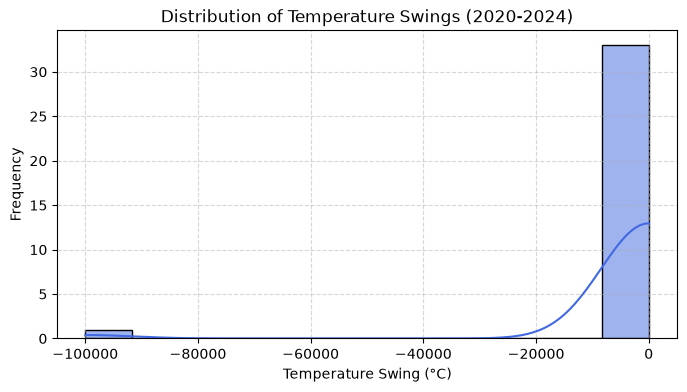

In [15]:
# ------------------------------------------
# STEP 2: Exploratory Data Analysis (EDA)
# ------------------------------------------
print("\n--- Step 2: Exploratory Data Analysis ---")

# Display basic statistical summary of the dataset
print(df_filtered[['Avg_Temp (°C)', 'Temp_Swing', 'Humidity (%)', 'Wind_Speed (m/s)']].describe())

# Plot distribution of Temperature Swings
plt.figure(figsize=(8, 4))
sns.histplot(df_filtered['Temp_Swing'], kde=True, color='royalblue')
plt.title('Distribution of Temperature Swings (2020-2024)')
plt.xlabel('Temperature Swing (°C)')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [16]:
# ------------------------------------------
# STEP 3: Feature Selection & Preparation
# ------------------------------------------
print("\n--- Step 3: Preparing Features for Model ---")

# Select independent feature columns that have robust numerical data
feature_cols = [
    'Solar_Irradiance (W/m²)', 
    'Cloud_Cover (%)', 
    'Humidity (%)', 
    'Wind_Speed (m/s)', 
    'Urbanization_Index'
]

# Drop rows where selected features contain NaN values
model_df = df_filtered.dropna(subset=feature_cols + ['Temp_Swing']).copy()

X = model_df[feature_cols]
y = model_df['Temp_Swing']

print(f"Dataset samples used for training: {len(model_df)}")


--- Step 3: Preparing Features for Model ---
Dataset samples used for training: 22


In [17]:
# ------------------------------------------
# STEP 4: Train-Test Split & Model Training
# ------------------------------------------
print("\n--- Step 4: Training Linear Regression Model ---")

# Split data into 80% Training and 20% Testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train the Linear Regression model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Display model coefficients
coefficients = pd.DataFrame(lr_model.coef_, X.columns, columns=['Coefficient'])
print("\nModel Feature Coefficients:")
print(coefficients)


--- Step 4: Training Linear Regression Model ---

Model Feature Coefficients:
                         Coefficient
Solar_Irradiance (W/m²)     0.052808
Cloud_Cover (%)             0.163938
Humidity (%)               -0.162428
Wind_Speed (m/s)            1.055358
Urbanization_Index         -2.818851



--- Step 5: Model Evaluation ---
R² Score: -1.0725
Mean Absolute Error (MAE): 10.6425
Root Mean Squared Error (RMSE): 13.1255


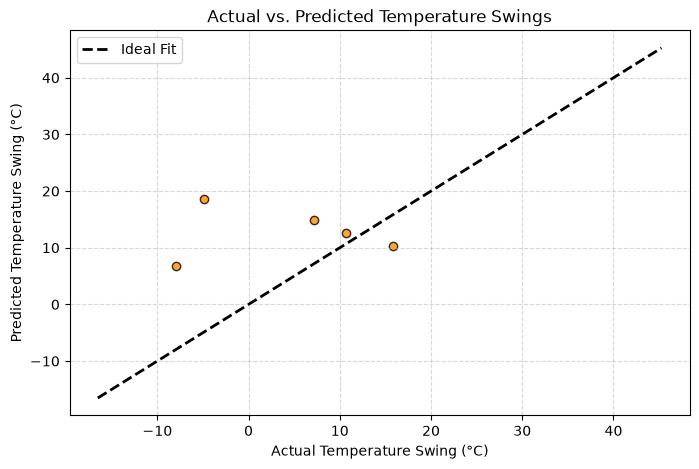

In [18]:
# ------------------------------------------
# STEP 5: Model Evaluation
# ------------------------------------------
print("\n--- Step 5: Model Evaluation ---")

# Predict on the test set
y_pred = lr_model.predict(X_test)

# Calculate evaluation metrics
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"R² Score: {r2:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")

# Plot Actual vs Predicted Temperature Swings
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, color='darkorange', edgecolors='black', alpha=0.8)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--', lw=2, label='Ideal Fit')
plt.title('Actual vs. Predicted Temperature Swings')
plt.xlabel('Actual Temperature Swing (°C)')
plt.ylabel('Predicted Temperature Swing (°C)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()